# 01. Data and baseline

**Notebook:** 01 of 4 · **Milestone:** M1 · **Code:** `src/evaluate.py` · **Enhancements:** E-008, E-022, E-007, E-023, E-024

This notebook answers two questions: what does the Colorado forest data look like, and how good is a plain model with no tuning? The second answer is the baseline, the number every later notebook has to beat.

Every experiment in Model Loop Lab gets its data and its scores from one file, `src/evaluate.py`. Steps 1 to 6 walk through that file and check each piece on the real Forest Covertype data. Steps 7 to 9 record the baseline and show where it goes wrong. Step 10 saves it for the website.

**Why one shared file?** If each notebook loaded data and scored models its own way, a better score might only mean a luckier split of the data. Sharing the code means every model on the site is judged on exactly the same plots, so the comparisons are fair.

The four pieces:

| Piece | Job |
|---|---|
| `load_covertype()` | Get the data and take a 20,000-plot sample |
| `make_split()` | Hold back 25% of the plots for testing |
| `evaluate()` | Train a model and score it on the held-out plots |
| `SEED` | One number that fixes every random step |

**To run in PyCharm:** open this file, choose the project's `.venv` as the kernel (top right of the notebook), then click **Run All**. The first run downloads about 11 MB of data into `data/`.

## Step 1. Setup

In [1]:
import sys
from pathlib import Path

# Let the notebook import from src/ (the project root is one folder up).
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier

from src.evaluate import (
    COVER_TYPES, SAMPLE_SIZE, SEED, TEST_SIZE,
    cover_type_report, evaluate, fit_predict, load_covertype, make_split,
)
from src.web_results import AMBER, GRAY, SPRUCE, save_web_chart

import matplotlib.pyplot as plt
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

pd.set_option("display.max_columns", 12)
print(f"Seed: {SEED}   Sample size: {SAMPLE_SIZE:,}   Test share: {TEST_SIZE:.0%}")

Seed: 42   Sample size: 20,000   Test share: 25%


This prints the three settings every experiment shares. They live in `src/evaluate.py`, so changing one there changes it everywhere at once.

## Step 2. Load the full dataset

### What we're looking for
How big the full dataset is, what a row looks like, and how common each of the seven forest cover types is. The last point matters for Step 3.

In [2]:
X_full, y_full = load_covertype(sample_size=None)
print(f"Plots: {len(X_full):,}   Features: {X_full.shape[1]}")
X_full.iloc[:5, :10]

Plots: 581,012   Features: 54


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points
0,2596.0,51.0,3.0,258.0,0.0,510.0,221.0,232.0,148.0,6279.0
1,2590.0,56.0,2.0,212.0,-6.0,390.0,220.0,235.0,151.0,6225.0
2,2804.0,139.0,9.0,268.0,65.0,3180.0,234.0,238.0,135.0,6121.0
3,2785.0,155.0,18.0,242.0,118.0,3090.0,238.0,238.0,122.0,6211.0
4,2595.0,45.0,2.0,153.0,-1.0,391.0,220.0,234.0,150.0,6172.0


### How to read it
Each row is one 30 by 30 meter plot of the Roosevelt National Forest. The first ten columns are map measurements: elevation in meters, aspect (compass direction the slope faces), slope in degrees, distances to water, roads and past fire points, and hillshade (how much sun the plot gets at 9am, noon and 3pm). The remaining 44 columns are yes/no flags: 4 for wilderness area and 40 for soil type.

In [3]:
full_counts = (
    y_full.value_counts().sort_index()
    .rename(index=COVER_TYPES).rename("plots").to_frame()
)
full_counts["share"] = (full_counts["plots"] / len(y_full)).map("{:.2%}".format)
full_counts

,plots,share
cover_type,,
Spruce/fir,211840,36.46%
Lodgepole pine,283301,48.76%
Ponderosa pine,35754,6.15%
Cottonwood/willow,2747,0.47%
Aspen,9493,1.63%
Douglas-fir,17367,2.99%
Krummholz,20510,3.53%


### How to read it
One row per cover type: how many plots have it and what share of all plots that is.

### What it means
The classes are very uneven. Lodgepole pine (48.8%) and Spruce/fir (36.5%) cover 85% of the forest, while Cottonwood/willow is under half a percent: 2,747 plots out of 581,012. A model can look good by getting the two big ones right and ignoring the rest, which is worth remembering whenever we read an accuracy number later.

### What's next and why
581,012 plots is too many to train models on over and over in a loop. The next step takes a smaller sample without losing the rare cover types.

### The same counts as a chart
Saved as `cover_types.png` for the project page and the presentation.

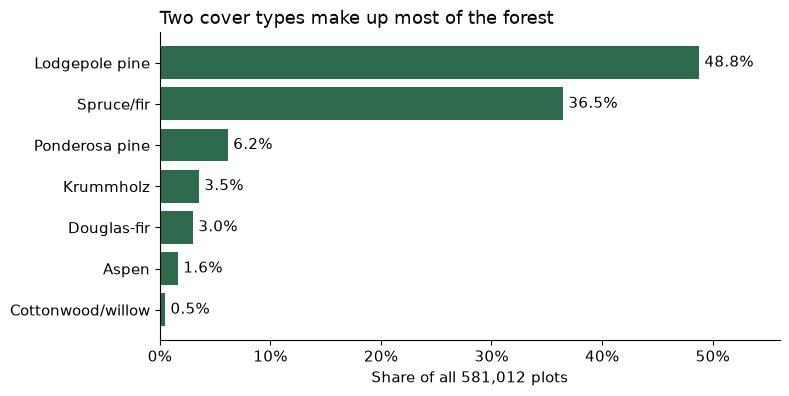

In [4]:
shares = (y_full.value_counts(normalize=True).rename(index=COVER_TYPES).sort_values())
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(shares.index, shares.values, color=SPRUCE)
for i, v in enumerate(shares.values):
    ax.text(v + 0.005, i, f"{v:.1%}", va="center")
ax.set_xlim(0, shares.max() * 1.15)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share of all 581,012 plots")
ax.set_title("Two cover types make up most of the forest", loc="left")
save_web_chart(fig, "cover_types")
plt.show()

### How to read it
One bar per cover type, longest at the top. The number at the end of each bar is its share of all plots. Lodgepole pine and Spruce/fir dwarf the rest; Cottonwood/willow barely shows.

## Step 3. Take the 20,000-plot sample

### What we're looking for
Whether the sample keeps each cover type's share. `load_covertype()` uses a **stratified** sample: it draws from each cover type in proportion to its size, instead of drawing 20,000 plots blindly. A blind draw could leave the rarest type with almost nothing.

In [5]:
X, y = load_covertype()   # default: 20,000 plots, seed 42
sample_counts = y.value_counts().sort_index().rename(index=COVER_TYPES)

compare = pd.DataFrame({
    "full share": (full_counts["plots"] / len(y_full)).map("{:.2%}".format),
    "sample plots": sample_counts,
    "sample share": (sample_counts / len(y)).map("{:.2%}".format),
})
print(f"Sample: {len(X):,} plots")
compare

Sample: 20,000 plots


,full share,sample plots,sample share
cover_type,,,
Spruce/fir,36.46%,7292,36.46%
Lodgepole pine,48.76%,9752,48.76%
Ponderosa pine,6.15%,1231,6.16%
Cottonwood/willow,0.47%,94,0.47%
Aspen,1.63%,327,1.64%
Douglas-fir,2.99%,598,2.99%
Krummholz,3.53%,706,3.53%


### How to read it
The first column is each cover type's share of the full forest. The next two are its count and share in the sample.

### What it means
The two share columns match to within a hundredth of a percent. Even Cottonwood/willow keeps its 0.47%, which is 94 plots in the sample. That's what stratifying buys us: the sample is a small but faithful copy of the forest, rare cover types included.

### What's next and why
Now the sample has to be split, so models can be trained on some plots and tested on plots they have never seen.

## Step 4. Split into training and held-out plots

### What we're looking for
A 75/25 split where no plot appears on both sides, and where both sides keep the same cover-type shares.

In [6]:
split = make_split(X, y)
overlap = set(split.X_train.index) & set(split.X_test.index)

shares = pd.DataFrame({
    "train share": split.y_train.value_counts(normalize=True).sort_index(),
    "test share": split.y_test.value_counts(normalize=True).sort_index(),
}).rename(index=COVER_TYPES).map("{:.2%}".format)

print(f"Training plots: {len(split.X_train):,}   Held-out plots: {len(split.X_test):,}   Plots in both: {len(overlap)}")
shares

Training plots: 15,000   Held-out plots: 5,000   Plots in both: 0


,train share,test share
cover_type,,
Spruce/fir,36.46%,36.46%
Lodgepole pine,48.76%,48.76%
Ponderosa pine,6.15%,6.16%
Cottonwood/willow,0.47%,0.46%
Aspen,1.63%,1.64%
Douglas-fir,2.99%,2.98%
Krummholz,3.53%,3.54%


### How to read it
The first line gives the size of each side and how many plots appear in both. The table compares cover-type shares in the training and held-out sets.

### What it means
15,000 plots to learn from, 5,000 to be tested on, and zero overlap. Testing on unseen plots is what makes a score honest. A model scored on plots it trained on can simply memorize them and look far better than it really is. Every score on the site comes from these same 5,000 held-out plots.

### What's next and why
With data and split fixed, the last piece is the scoring function itself.

## Step 5. Score models with `evaluate()`

### What we're looking for
Two scores that frame everything that follows:

* **Guessing**: a "model" that always predicts the most common cover type. Any real model has to beat this to be worth anything.
* **A plain decision tree** with default settings. This is a preview of the baseline, recorded properly in the steps that follow.

In [7]:
guess = evaluate(DummyClassifier(strategy="most_frequent"), split)
tree = evaluate(DecisionTreeClassifier(random_state=SEED), split)

print(f"Always guess the most common type: {guess:.1%}")
print(f"Plain decision tree:               {tree:.1%}")

Always guess the most common type: 48.8%
Plain decision tree:               77.2%


### How to read it
Each number is accuracy: the share of the 5,000 held-out plots where the predicted cover type was right.

### What it means
Guessing scores 48.8%, exactly Lodgepole pine's share, because Lodgepole pine is the only answer it ever gives. The decision tree, which actually looks at elevation, soil and the rest, scores 77.2%. That 28-point gap is how much the map features tell us about which trees grow where.

### What's next and why
Before trusting `evaluate()` inside a loop that calls it hundreds of times, we need to know it gives the same answer every time and has no side effects.

## Step 6. Check that scoring is repeatable

### What we're looking for
Two things the evolution loop depends on: scoring the same settings twice gives the identical number, and the model passed in is left untouched (`evaluate()` trains a copy).

In [8]:
model = DecisionTreeClassifier(random_state=SEED)
first = evaluate(model, split)
second = evaluate(model, split)

print(f"First score:  {first:.4f}")
print(f"Second score: {second:.4f}")
print(f"Identical: {first == second}")
print(f"Original model still untrained: {not hasattr(model, 'tree_')}")

First score:  0.7718
Second score: 0.7718
Identical: True
Original model still untrained: True


### How to read it
Both scores, whether they match exactly, and whether the model object we passed in was changed.

### What it means
Identical scores and an untrained original mean any difference between two models in the loop comes from their settings, not from chance or from one run leaking into the next.

### What's next and why
The shared pieces work on the real data. Now they can be trusted to record the official baseline.

## Step 7. Record the baseline

### What we're looking for
The **baseline**: the accuracy of a decision tree with every setting left at its default. Nobody chose its settings, so it shows how well a model does with zero tuning. Every improvement the evolution loop claims in notebook 02 is measured against this number.

We also score the tree on the plots it trained on. Comparing the two scores shows whether the tree learned general patterns or just memorized its training plots.

In [9]:
baseline_model = DecisionTreeClassifier(random_state=SEED)
fitted, predictions = fit_predict(baseline_model, split)

baseline = evaluate(baseline_model, split)
train_score = fitted.score(split.X_train, split.y_train)

print(f"Baseline accuracy on held-out plots: {baseline:.2%}")
print(f"Accuracy on its own training plots:  {train_score:.2%}")
print(f"Tree size: {fitted.get_depth()} levels deep, {fitted.get_n_leaves():,} leaves")
print(f"Wrong on {int(round((1 - baseline) * len(split.y_test))):,} of {len(split.y_test):,} held-out plots")

Baseline accuracy on held-out plots: 77.18%
Accuracy on its own training plots:  100.00%
Tree size: 33 levels deep, 2,341 leaves
Wrong on 1,141 of 5,000 held-out plots


### How to read it
The first line is the baseline. The second is the same tree scored on the 15,000 plots it learned from. The third line gives the tree's size: each level is one more yes/no question, and each leaf is a final answer. The last line turns the baseline into a count of mistakes.

### What it means
The baseline is **77.2%**: the tree is wrong on 1,141 of the 5,000 plots it has never seen. On its own training plots it scores a perfect 100%. A default tree keeps asking yes/no questions until every training plot is sorted, and this one needed 33 levels and 2,341 leaves to do it, which works out to about one leaf for every six training plots. Many of those leaves describe single, unusual plots.

The 23-point drop from 100% to 77.2% is **overfitting**: the tree memorized details of its training plots that don't carry over to new ones.

That gap is exactly what the evolution loop can work on. Settings such as maximum depth and minimum leaf size stop a tree from memorizing, and other model types average many trees together. The loop's job is to find the combination that closes the gap.

### What's next and why
A single accuracy number hides where the mistakes are. With cover types this uneven, the tree could be strong on the common types and weak on the rare ones.

### The baseline in one chart
Saved as `baseline_scores.png`.

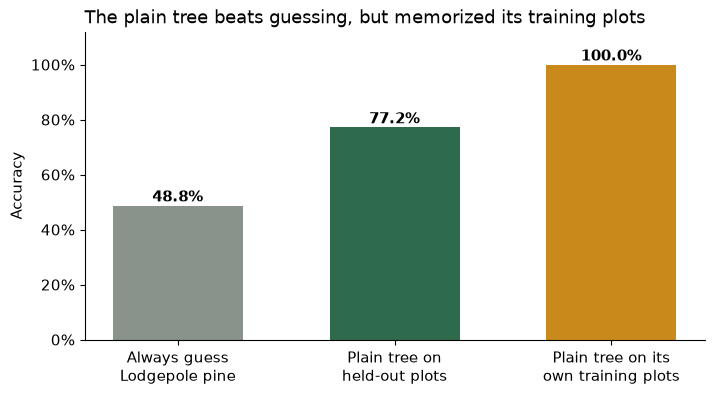

In [10]:
labels = ["Always guess\nLodgepole pine", "Plain tree on\nheld-out plots", "Plain tree on its\nown training plots"]
values = [guess, baseline, train_score]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, values, color=[GRAY, SPRUCE, AMBER], width=0.6)
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.1%}", ha="center", fontweight="bold")
ax.set_ylim(0, 1.12)
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_ylabel("Accuracy")
ax.set_title("The plain tree beats guessing, but memorized its training plots", loc="left")
save_web_chart(fig, "baseline_scores")
plt.show()

### How to read it
Gray is the floor: always guessing the most common cover type. Green is the baseline, the plain tree on plots it never saw. Amber is the same tree on the plots it learned from. The gap between green and gray is what the map features are worth. The gap between amber and green is overfitting.

## Step 8. Which cover types does the baseline get right?

### What we're looking for
For each cover type: how many held-out plots it has, how many the tree got right (**recall**), and how trustworthy the tree's answer is when it names that type (**precision**). Rare cover types are where a model is most likely to struggle.

In [11]:
report = cover_type_report(split.y_test, predictions)
shown = report.copy()
for col in ["recall", "precision"]:
    shown[col] = shown[col].map("{:.1%}".format)
shown

,plots,correct,recall,precision
cover_type,,,,
Spruce/fir,1823,1397,76.6%,76.6%
Lodgepole pine,2438,1958,80.3%,81.3%
Ponderosa pine,308,239,77.6%,74.0%
Cottonwood/willow,23,15,65.2%,55.6%
Aspen,82,36,43.9%,44.4%
Douglas-fir,149,78,52.3%,52.0%
Krummholz,177,136,76.8%,72.3%


### How to read it
* **plots**: how many of the 5,000 held-out plots really are this cover type
* **correct**: how many of those the tree labeled correctly
* **recall**: correct ÷ plots. "Of the real Aspen plots, how many did the tree find?"
* **precision**: of every plot the tree *called* this type, the share that really were. "When the tree says Aspen, how often is it right?"

### What it means
The two big cover types sit near the overall score: Lodgepole pine 80% and Spruce/fir 77%. The weak spots are **Aspen (44%)**, **Douglas-fir (52%)** and **Cottonwood/willow (65%)**, three of the four rarest types. Aspen is the clearest problem: the tree finds fewer than half the real Aspen plots, and when it does say Aspen it's right only 44% of the time.

Rarity isn't the whole story, though. Krummholz is rare too (177 held-out plots), yet the tree finds 77% of it, about as well as the common types. The next chart suggests why: it depends on which cover types each one can be mistaken for.

One caution about small numbers: with only 23 Cottonwood/willow plots held out, each one moves its recall by more than 4 points, so treat its rate as rough.

### What's next and why
The table says how often each type is missed but not what it gets mistaken for. The next chart shows that.

### Recall by cover type as a chart
Saved as `cover_type_recall.png`.

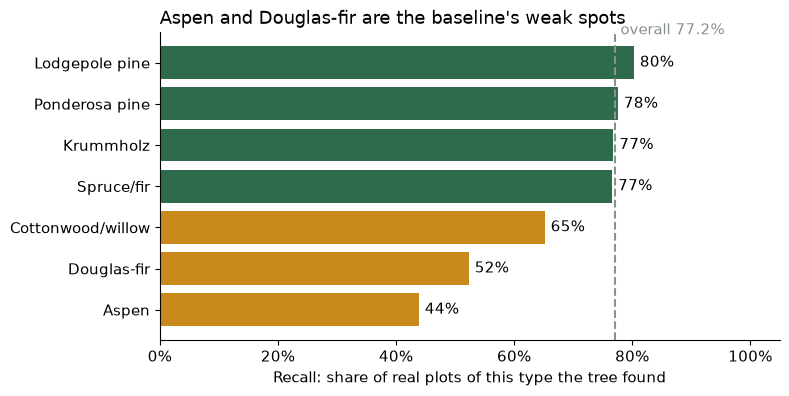

In [12]:
recall = report["recall"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
weak = baseline - 0.05   # more than 5 points below the overall score
colors = [AMBER if v < weak else SPRUCE for v in recall.values]
ax.barh(recall.index, recall.values, color=colors)
ax.axvline(baseline, color=GRAY, linestyle="--", linewidth=1.5)
ax.text(baseline, len(recall) - 0.4, f" overall {baseline:.1%}", color=GRAY, va="bottom")
for i, v in enumerate(recall.values):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center")
ax.set_xlim(0, 1.05)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Recall: share of real plots of this type the tree found")
ax.set_title("Aspen and Douglas-fir are the baseline's weak spots", loc="left")
save_web_chart(fig, "cover_type_recall")
plt.show()

### How to read it
One bar per cover type, weakest at the bottom. The dashed line is the overall accuracy. Amber bars are more than 5 points below it, the cover types the baseline clearly struggles with; green bars are within 5 points of it or above.

## Step 9. What gets confused with what?

### What we're looking for
Patterns in the mistakes. Cover types that grow in similar places, at similar elevations and on similar soils, should be the ones the tree mixes up.

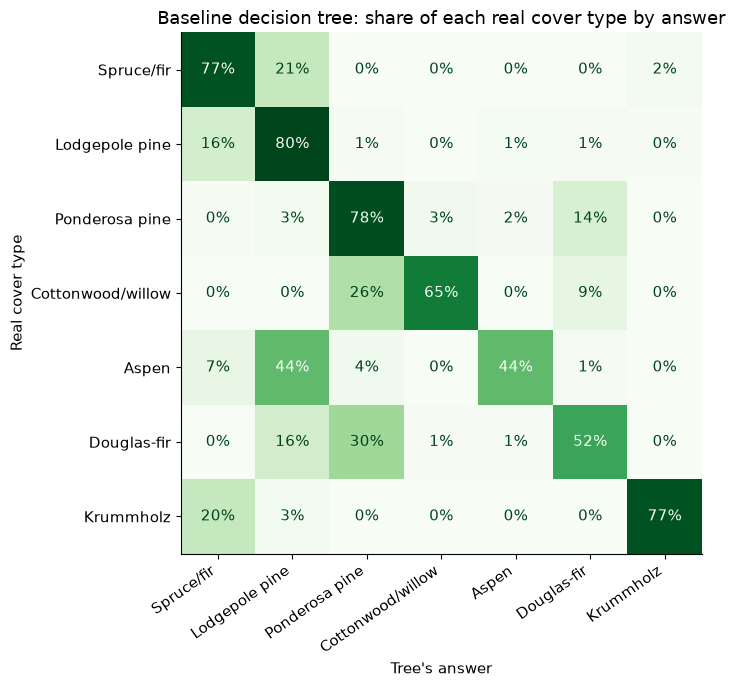

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay

names = list(COVER_TYPES.values())
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    split.y_test, predictions,
    labels=list(COVER_TYPES), display_labels=names,
    normalize="true", values_format=".0%", cmap="Greens", colorbar=False, ax=ax,
)
ax.set_xlabel("Tree's answer")
ax.set_ylabel("Real cover type")
ax.set_title("Baseline decision tree: share of each real cover type by answer")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
save_web_chart(fig, "confusion")
plt.show()

### How to read it
Each row is a real cover type and adds up to 100% across. Each column is the tree's answer. The diagonal from top left to bottom right shows correct answers, the same numbers as the recall column in Step 8. Any other shaded square is a mistake: the row's cover type was called the column's.

### What it means
The mistakes fall into neighbor pairs, cover types that share elevations and soils:

* **Spruce/fir and Lodgepole pine** swap with each other: 21% of Spruce/fir is called Lodgepole pine, and 16% of Lodgepole pine is called Spruce/fir. Because these two are 85% of all plots, this pair alone causes most of the 1,141 mistakes.
* **Aspen** is called Lodgepole pine 44% of the time, as often as it's called Aspen. Aspen tends to grow mixed in with lodgepole stands, so the map features look nearly the same.
* **Douglas-fir** is called Ponderosa pine 30% of the time, and **Cottonwood/willow** is called Ponderosa pine 26% of the time. These are the low-elevation types.
* **Krummholz**, the stunted trees at treeline, is only ever confused with Spruce/fir (20%), its neighbor just below it on the mountain. That is why it does well despite being rare: it has only one look-alike.

Those neighbor pairs are where a better model has the most to gain. A model that separates Spruce/fir from Lodgepole pine even a little better will raise the overall score more than anything else.

### What's next and why
The baseline is recorded. The last step saves it where the website can read it.

### Why the neighbors get confused: elevation
Elevation is the strongest single clue to which trees grow on a plot. If two cover types grow over the same range of elevations, the tree has to rely on weaker clues to tell them apart. Saved as `elevation_by_type.png`.

C:\Users\sschi\AppData\Local\Temp\ipykernel_22028\4269277693.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box = ax.boxplot(data, vert=False, tick_labels=list(order), patch_artist=True, showfliers=False, widths=0.6)


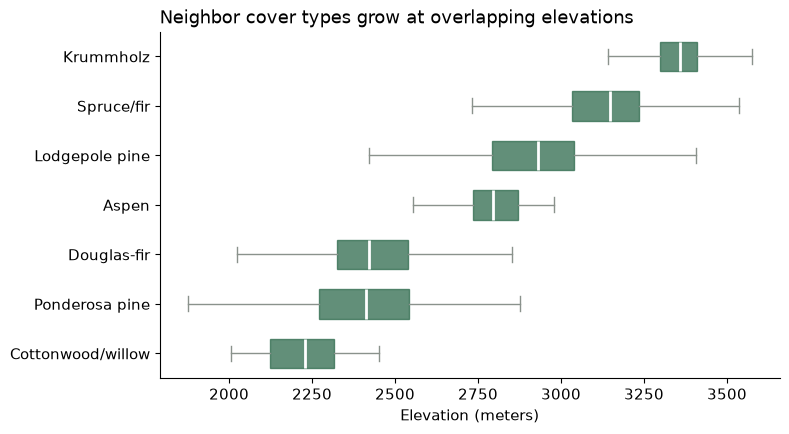

In [14]:
order = (X.assign(cover=y.map(COVER_TYPES)).groupby("cover")["Elevation"].median().sort_values().index)
data = [X.loc[y.map(COVER_TYPES) == name, "Elevation"] for name in order]
fig, ax = plt.subplots(figsize=(8, 4.5))
box = ax.boxplot(data, vert=False, tick_labels=list(order), patch_artist=True, showfliers=False, widths=0.6)
for patch in box["boxes"]:
    patch.set(facecolor=SPRUCE, alpha=0.75, edgecolor=SPRUCE)
for part in ("whiskers", "caps"):
    for line in box[part]:
        line.set(color=GRAY)
for line in box["medians"]:
    line.set(color="white", linewidth=2)
ax.set_xlabel("Elevation (meters)")
ax.set_title("Neighbor cover types grow at overlapping elevations", loc="left")
save_web_chart(fig, "elevation_by_type")
plt.show()

### How to read it
One row per cover type, lowest-growing at the bottom. Each box covers the middle half of that cover type's plots, the white line is the middle (median) plot, and the gray lines reach out to the typical lowest and highest plots.

### What it means
The cover types form a ladder up the mountain: Cottonwood/willow, Ponderosa pine and Douglas-fir at the bottom, Lodgepole pine and Aspen in the middle, Spruce/fir above them, Krummholz at treeline. Where boxes overlap, elevation alone can't tell the trees apart, and those are the same pairs the confusion chart showed being mixed up. Krummholz overlaps mainly with Spruce/fir, just below it on the mountain, which is why it has essentially one look-alike.

### What's next and why
The baseline and its weaknesses are now clear. The last step saves the baseline where the website can read it.

## Step 10. Save the baseline for the website

### What we're looking for
A small file, `results/web/baseline.json`, holding the baseline and how it was measured. When `scripts/build_site.py` runs, this file replaces the site's sample baseline. "Starting accuracy" on the overview and the dashed "Starting model" line on The loop works page then show the real number, and their "Sample data" tags go away.

In [15]:
from src.web_results import save_web_result

path = save_web_result("baseline", {
    "label": "Default decision tree",
    "score": round(baseline, 4),
    "train_score": round(train_score, 4),
    "held_out_plots": len(split.y_test),
    "training_plots": len(split.y_train),
    "tree_depth": int(fitted.get_depth()),
    "tree_leaves": int(fitted.get_n_leaves()),
    "seed": SEED,
})
print(f"Saved {path.relative_to(PROJECT_ROOT)}")
print(path.read_text(encoding="utf-8"))

Saved results\web\baseline.json
{
 "sample": false,
 "recorded": "2026-11-20",
 "label": "Default decision tree",
 "score": 0.7718,
 "train_score": 1.0,
 "held_out_plots": 5000,
 "training_plots": 15000,
 "tree_depth": 33,
 "tree_leaves": 2341,
 "seed": 42
}


### How to read it
The path of the saved file, then its contents. `"sample": false` marks it as real data. `"recorded"` is today's date. The other fields are the numbers from Step 7.

### What it means
The site and the notebook now share one source for the baseline. If the data or the seed ever changes, rerunning this notebook and the build updates the site with no hand edits, so the two can never disagree.

### What's next and why
Run the build to put the number on the site:

```
python scripts/build_site.py
```

The build should list `baseline.json` under "Real results used." Then notebook 02 starts the evolution loop and tries to beat this number.

## Summary

| Check | Result |
|---|---|
| Full dataset | 581,012 plots, 54 features, 7 cover types |
| Sample | 20,000 plots, cover-type shares kept |
| Split | 15,000 training / 5,000 held-out, no overlap |
| Scoring | Repeatable, never changes the model passed in |
| Baseline | Default decision tree: **77.2%** held out, 100% on training plots (Step 7) |
| Weak spots | Aspen 44%, Douglas-fir 52%, Cottonwood/willow 65%; Spruce/fir and Lodgepole pine confused with each other (Steps 8 and 9) |
| Saved for the site | `results/web/baseline.json`, Step 10 |

The data and scoring checks also run automatically in `tests/test_evaluate.py` every time `python -m pytest` runs, on a small made-up dataset so they don't need the download.